# Social Media Engagement Analytics Using Python


In this project , I am performing an end to end data analytics workflow on social media engagement dataset using Python in jupyter Notebook. The objective is to understand social media engagement patterns, identify trends, analyse content performance, and generate meaningful insights from the available data.I will follow a structured approach starting from data loading and initial inspection, followed by data cleaning and preprocessing. After preparing the dataset, I will perform exploratory data anlysis(EDA), visualization, and finally generate insights based on the analysis.

1.**Importing Required Libraries**


Before starting the data analysis ,I first import the required Python libraries. These libraries provide the necessary tools for data manipulation,numerical operations , and data visualization.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Numpy** is used for numerical operations and array-based calculations.                                                                               
**Pandas** is used to load ,inspect, clean and manipulate the tabular dataset.                                                                         
**Matplotlib** is used to create basic datavisualizations such as line charts,bar charts, scatter plots,histogram, and box plots.                      
**Seaborn** is used to create statistical visualizations and improve the presentation of analytical charts,

2.**Loading the Dataset**

In this step, I load the social media engagement datset into a Pandas Dataframe.The dataset contains informations about social media posts,including user details, post types, categories and engagement -related matrics.Loading the datset into a DataFrame allowsme to inspect ,clean ,transform and analyse the data usingPython.

In [2]:
df=pd.read_csv("social_media_engagement_5000.csv")

In [3]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


**3.Initial Data Inspection**

After loading the dataset, I perform an initial inspection to understand its structure and characteristics.

This step helps identify the number of rows and columns, examine the data types of each column, and check whether the dataset contains missing values.

Understanding the dataset before cleaning and analysis helps ensure that the data is suitable for further processing and exploratory data analysis.


In [4]:
df.shape

(5000, 19)

This will tell us the number of rows and columns in our dataset

**3.1 Checking Dataset Information**

The `df.info()` function provides a summary of the dataset. It shows the column names, the number of non-null values, the data types of each column, and the memory usage of the DataFrame.

This helps me understand the structure of the dataset and identify columns that may contain missing values or require data type conversion during the data cleaning process.



In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

**3.2 Checking for Mssing Values**

After checking the basic information of the dataset, I check for missing values in each column.

Identifying missing values is an important part of data cleaning because missing data can affect calculations, visualizations, and the accuracy of the analysis.


In [7]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

**3.3 Checking Data Types**

In this step, I check the data type of each column in the dataset. This helps ensure that numerical columns are stored as numeric values, categorical columns are stored appropriately, and date columns can be converted to datetime format.

Checking data types before analysis helps prevent errors during calculations, filtering, and visualization.

In [9]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

**3.4 Converting Date Column**

The posted_at column is currently stored as a string. I convert it to datetime format so that dates can be properly used for sorting, filtering, and time-based analysis.

In [6]:
df['posted_at']=pd.to_datetime(df['posted_at'],dayfirst=True)

In [11]:
df['posted_at']

0      2022-12-17
1      2023-06-02
2      2023-05-07
3      2023-02-12
4      2023-05-23
          ...    
4995   2022-06-25
4996   2022-11-18
4997   2023-04-06
4998   2022-05-16
4999   2023-03-04
Name: posted_at, Length: 5000, dtype: datetime64[us]

**3.5 Using NumPy Arrays**

NumPy arrays are used for efficient numerical operations. In this step, I convert the engagement-related columns into a NumPy array and calculate basic statistics.



In [4]:
engagement_array= df[['likes','comments','shares']].to_numpy()
engagement_array

array([[ 7011.,   354.,  1157.],
       [11750.,  2606.,  1807.],
       [ 4862.,   344.,   955.],
       ...,
       [13487.,    nan,   167.],
       [16894.,  1289.,  1713.],
       [14830.,   503.,  1798.]], shape=(5000, 3))

In [6]:
engagement_array[:8]

array([[ 7011.,   354.,  1157.],
       [11750.,  2606.,  1807.],
       [ 4862.,   344.,   955.],
       [ 5350.,  1083.,  1049.],
       [12682.,  2735.,  1300.],
       [12535.,  1790.,    99.],
       [11703.,  2276.,  1465.],
       [ 9611.,   146.,   424.]])

I used np.nanmean() to calculate  the average engagement while ignoring missing values.The nanmean() function is useful because the dataset contains missing values.

In [9]:
np.nanmean(engagement_array, axis=0)

array([10107.04371134,  1502.1956701 ,  1002.62948454])

**4. Cleaning Missing Data**

After identifying missing values , I handle them appropriately to improve the quality and reliability of the datasetbefore further analysis.

1.Fill Numerical missing values with median
   

In [12]:
df['age']=df['age'].fillna(df['age'].median())
df['likes']=df['likes'].fillna(df['likes'].median())
df['comments']=df['comments'].fillna(df['comments'].median())
df['shares']=df['shares'].fillna(df['shares'].median())

2.Fill Categorical missing values with mode function

In [15]:
df['gender']=df['gender'].fillna(df['gender'].mode()[0])
df['sentiment']=df['sentiment'].fillna(df['sentiment'].mode()[0])

Next I checked all missing values are removed

df.isnull().sum()

**5.Duplicate Handling**

After handling the missing values, I check the dataset for duplicate records. Duplicate rows can affect the accuracy of the analysis by counting the same record more than once.                                                                                                                         The duplicated() function identifies rows that are repeated in the dataset, and sum() counts the total number of duplicate rows.
This step helps ensure that each record is unique and prevents duplicate data from affecting the analysis.

In [3]:
df.duplicated().sum()

np.int64(0)

The duplicate check returned 0, which means that there are no duplicate rows in the dataset.
Since the dataset does not contain any duplicate records, no rows need to be removed. The dataset can therefore be used for further data cleaning and analysis without applying a duplicate-removal operation

**6.Data Formating**

I checked the data types of the columns to ensure that numerical, categorical, and date columns are stored in the appropriate format. Correct data types help prevent errors during analysis and calculations.

In [7]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [8]:
df['gender'].value_counts()

gender
Male      1699
Other     1581
Female    1570
Name: count, dtype: int64

I checked the unique gender categories using value_counts(). The dataset contains three consistent categories: Male, Female, and Other. No standardization was required




In [9]:
df[['likes','comments','shares']].describe()

,likes,comments,shares
count,4850.000000,4850.000000,4850.000000
mean,10107.043711,1502.195670,1002.629485
std,5789.819252,869.537889,579.615158
min,10.000000,0.000000,0.000000
25%,5068.500000,760.000000,498.000000
50%,10105.500000,1497.000000,1012.000000
75%,15115.000000,2256.000000,1501.000000
max,19998.000000,2999.000000,1999.000000


In [10]:
df[['likes','comments','shares']].min()

likes       10.0
comments     0.0
shares       0.0
dtype: float64

I checked the likes, comments, and shares columns for unrealistic negative values. The minimum values are within a valid range, so no unrealistic values were found and no changes were required.

**6. Feature Cleaning**

Extract Hashtag count.-
I extracted the number of hastags from the hashtags and created a new column called hashtag_count.


In [12]:
df['hashtag_count']=df['hashtags'].str.count('#')

In [16]:
df['hashtag_count'].head(10)

0    3
1    1
2    1
3    3
4    1
5    1
6    1
7    3
8    3
9    2
Name: hashtag_count, dtype: int64

Clean Sentiment labels- 

In [17]:
df['sentiment'].value_counts()

sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64

In [18]:
df['sentiment'].unique()

<StringArray>
['negative', 'positive', 'neutral', nan]
Length: 4, dtype: str

In [19]:
df['sentiment'].isna().sum()

np.int64(150)

I checked the sentiment column for missing values using isna().sum(). The result showed 150 missing values(NaN).

In [20]:
df['sentiment']=df['sentiment'].fillna('neutral')

In [21]:
df['sentiment'].unique()

<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

I replaced the 150 missing sentiment values with neutral using fillna().then I checked unique values to verify the cleaning.

**7.Data Exploration using Pandas**

In [4]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


I used head() to view the first five rows of the dataset and verify that the data is structured correctly after the cleaning process.

In [5]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


I used tail to view the last five rows of the data set.This helps verify the ending records and confirm that the datset is loaded correctly.

In [7]:
df.shape

(5000, 19)

I used shape to identify the number of rows and columns in the dataset.

In [8]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

I used df.columns to view all the column names .

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

I used df.info() to check the structure of the dataset, including the number of rows, columns, non -null values, and data types.. It also helped identify columns containing missing values.

In [10]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [11]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
count,5000.000000,4850.000000,5000.000000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,393698.224800,0.964356
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,230927.884535,5.318029
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5068.500000,760.000000,498.000000,2017.750000,24988.250000,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,799533.000000,191.504348


I used df.describe() to generate summary statistics for the numerical columns, including count, mean, standard deviation, minimum, maximum, median, and percentiles.



* Correlation Matrix
 
   A correlation matrix is used to examine the relationships between numerical variables in the dataset. It shows whether variables have positive, negative, or weak relationships with each other.

In [12]:
correlation_matrix= df.corr(numeric_only=True)
correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,is_verified,engagement_rate
user_id,1.000000,-0.006789,0.020051,0.026228,-0.033874,0.014004,-0.016847,0.015326,0.010124,0.004058,-0.004282
age,-0.006789,1.000000,-0.013353,-0.037371,-0.007491,0.014348,0.005677,0.013513,-0.025416,-0.000112,0.008044
post_id,0.020051,-0.013353,1.000000,0.014773,-0.010724,0.001901,0.018374,-0.007709,-0.002844,0.025208,0.010139
likes,0.026228,-0.037371,0.014773,1.000000,-0.018980,0.004799,0.008837,0.008067,-0.023331,-0.016395,0.093555
comments,-0.033874,-0.007491,-0.010724,-0.018980,1.000000,0.006310,-0.016616,-0.009537,-0.011921,-0.012577,0.000046
shares,0.014004,0.014348,0.001901,0.004799,0.006310,1.000000,0.014898,-0.005178,-0.010891,0.007158,0.021804
watch_time_sec,-0.016847,0.005677,0.018374,0.008837,-0.016616,0.014898,1.000000,-0.004335,0.002761,0.012326,-0.001148
impression_count,0.015326,0.013513,-0.007709,0.008067,-0.009537,-0.005178,-0.004335,1.000000,-0.015513,0.008317,-0.232226
follower_count,0.010124,-0.025416,-0.002844,-0.023331,-0.011921,-0.010891,0.002761,-0.015513,1.000000,-0.017808,0.002292
is_verified,0.004058,-0.000112,0.025208,-0.016395,-0.012577,0.007158,0.012326,0.008317,-0.017808,1.000000,0.005528


Next I calculated the average number of likes for each post type by groupby() function.

In [13]:
df.groupby('post_type')['likes'].mean()

post_type
image    10104.848560
reel     10035.341680
text     10099.975124
video    10190.972292
Name: likes, dtype: float64

Then I compared the reach of social media posts across different countries by groupby function.

In [17]:
df.groupby('country')['impression_count'].sum()

country
Australia    23834767
Brazil       24793360
Canada       24984716
France       25656926
Germany      23816649
India        28067377
Japan        23418816
UAE          24610992
UK           25201861
USA          25683200
Name: impression_count, dtype: int64

In [19]:
df.groupby('sentiment')['likes'].mean()

sentiment
negative    10211.406452
neutral      9917.785570
positive    10158.542994
Name: likes, dtype: float64

**8. Statistical Analysis**

In [20]:
metrics=['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']
df[metrics].mean()
df[metrics].median()

likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

In [21]:
df[metrics].mode().iloc[0]

likes                6486.000000
comments             2934.000000
shares                138.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

In [22]:
df[metrics].std()

likes                5789.819252
comments              869.537889
shares                579.615158
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

In [23]:
df[metrics].var()

likes              3.352201e+07
comments           7.560961e+05
shares             3.359537e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [25]:
df[metrics].quantile([0.25,0.50,0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5068.5,760.0,498.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.0,1012.0,4034.50,0.253896,388982.00
0.75,15115.0,2256.0,1501.0,6020.25,0.504794,589744.25


I calculated the mean, median, and mode,standard deviation, variance, percentile for the main numerical metrics in the dataset, including likes, comments, shares, watch time, engagement rate, and follower count

In [26]:
 df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

## Data Visualization

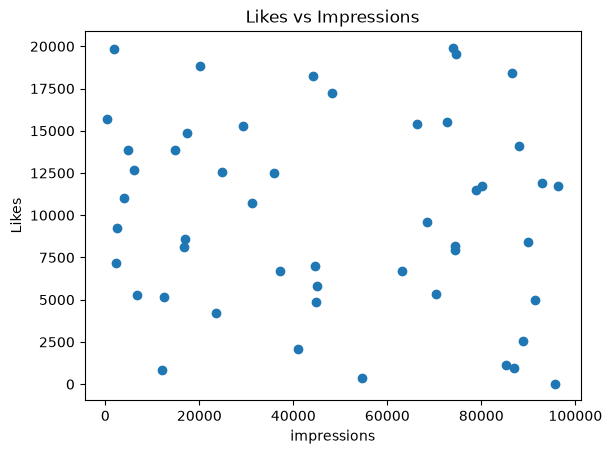

In [29]:
plt.scatter(df['impression_count'].head(50),df['likes'].head(50))
plt.xlabel('impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')
plt.show()

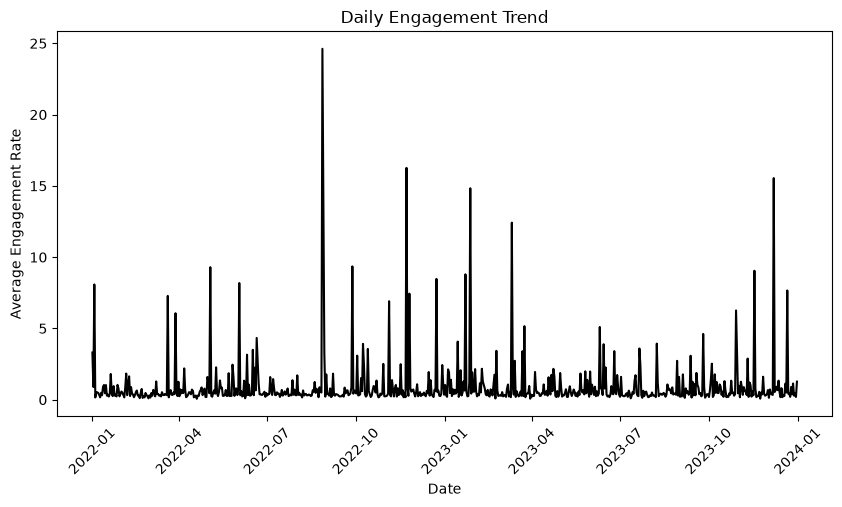

In [43]:
df['posted_at'] = pd.to_datetime(df['posted_at'])

daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_rate'].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_engagement.index, daily_engagement.values,color='black')

plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.title('Daily Engagement Trend')
plt.xticks(rotation=45)

plt.show()

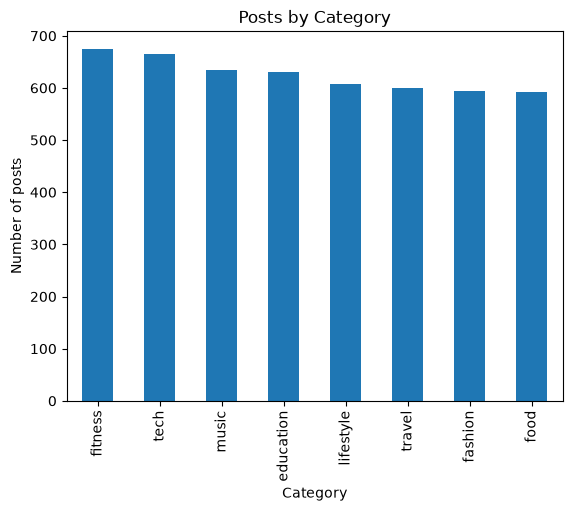

In [33]:
df['post_category'].value_counts().plot(kind='bar')
plt.xlabel('Category')
plt.ylabel('Number of posts')
plt.title('Posts by Category')
plt.show()

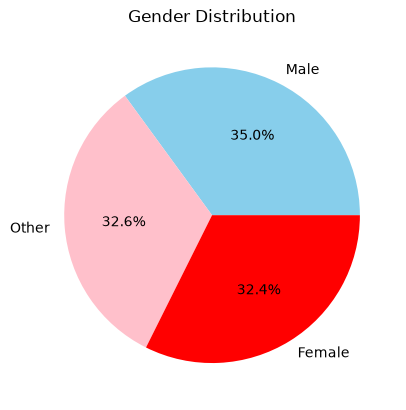

In [37]:
df['gender'].value_counts().plot(kind='pie',autopct='%1.1f%%',colors=['skyblue','pink','red'])

plt.ylabel('')
plt.title('Gender Distribution')
plt.show()

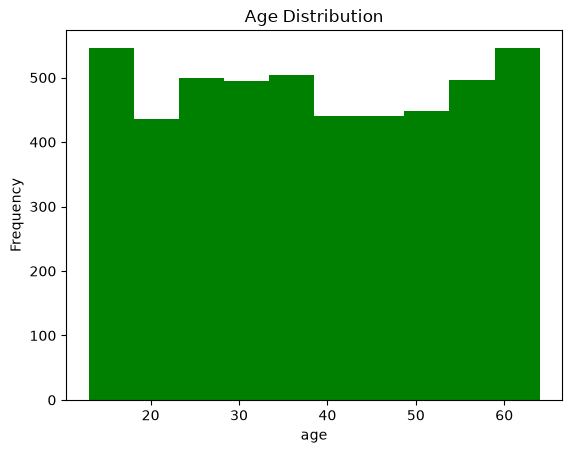

In [40]:
df['age'].plot(kind='hist',bins=10,color='green')
plt.xlabel('age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

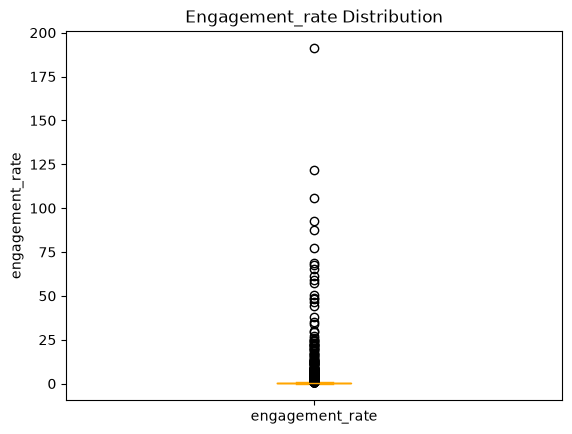

In [41]:
df['engagement_rate'].plot(kind='box',color='orange')
plt.ylabel('engagement_rate')
plt.title('Engagement_rate Distribution')
plt.show()

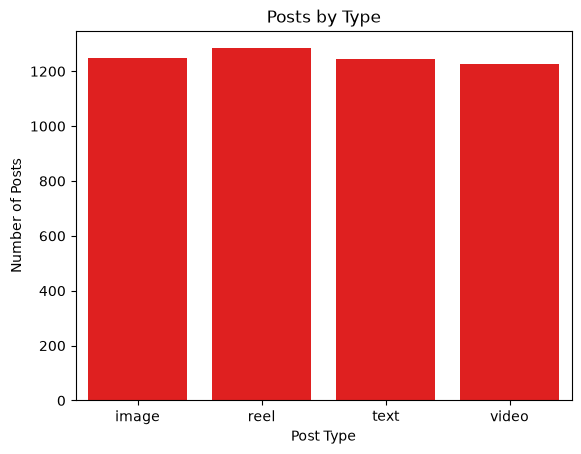

In [45]:
sns.countplot(data=df, x='post_type',color='red')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.title('Posts by Type')
plt.show()

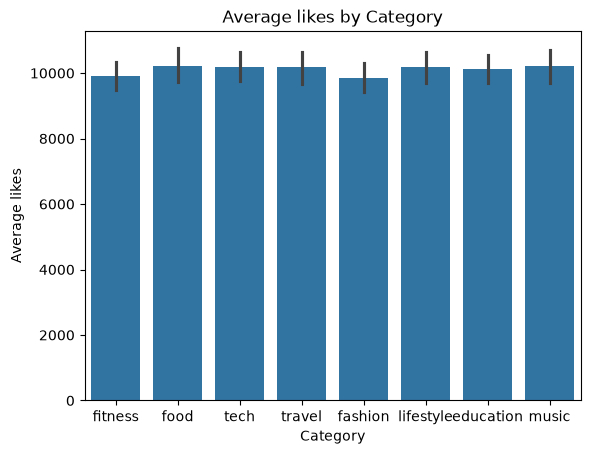

In [46]:
sns.barplot(data=df, x='post_category',y='likes')
plt.xlabel('Category')
plt.ylabel('Average likes')
plt.title('Average likes by Category')
plt.show()

## Final Insights 

### Highest-Engagement Post Type

I compared the average engagement rate for each post type to identify which type of content performs best.

In [48]:
df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

### Best-Performing content category

I compared the average engagement rate for each content category to identify which type of content performs best.

In [49]:
df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

### Country with highest Engagement rate

I compared the average engagement rate across countries  to identify which country has the highest engagement .

In [50]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

### How age affects engagement

I grouped users  into age ranges and compared their average engagement rate to understand how age is related toengagement.

In [60]:
df['age_group']=pd.cut(df['age'],bins=[0,18,25,35,45,60,100],labels=['Under 18','18-25','26-35','36-45','46-60','60+'])


In [61]:
df.groupby('age_group')['engagement_rate'].mean()

age_group
Under 18    0.867038
18-25       1.059536
26-35       0.865316
36-45       0.858642
46-60       1.152669
60+         0.801381
Name: engagement_rate, dtype: float64

### Performance Difference for Verified Accounts


I compared the average engagement rate of verified and non-verified accounts to understand whether verification affects engagement.


In [62]:
df.groupby('is_verified')['engagement_rate'].mean()

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64

### Best Time of Day for Impressions

In [70]:
df['hour']=df['posted_at'].dt.hour


In [74]:
df.groupby('hour')['impression_count'].mean()

hour
0    50013.7328
Name: impression_count, dtype: float64

The highest available impressions are recorded at 12 AM, with an average of about 50,014 impressions.


### Device Type Impact on watch time

In [78]:
df.groupby('device_type')['watch_time_sec'].mean()

device_type
desktop    3974.792521
mobile     4087.830760
tablet     3979.736429
Name: watch_time_sec, dtype: float64

Mobile users have the highest average watch time, followed by tablet and desktop users.


### Sentimental Analysis

In [79]:
df.groupby('sentiment')['engagement_rate'].mean()

sentiment
negative    1.038486
neutral     0.991170
positive    0.954800
Name: engagement_rate, dtype: float64

The results shows that negative sentiment has the highest engagement rate ,followed by neutral and positive sentiment.

## Conclusion

This project analyzed social media engagement using Python, Pandas, NumPy, and data visualization techniques. The analysis explored user demographics, post types, engagement rates, countries, age groups, device types, sentiment, and impressions.

The analysis helped identify important patterns in user engagement and provided useful insights into social media activity and audience behavior.
